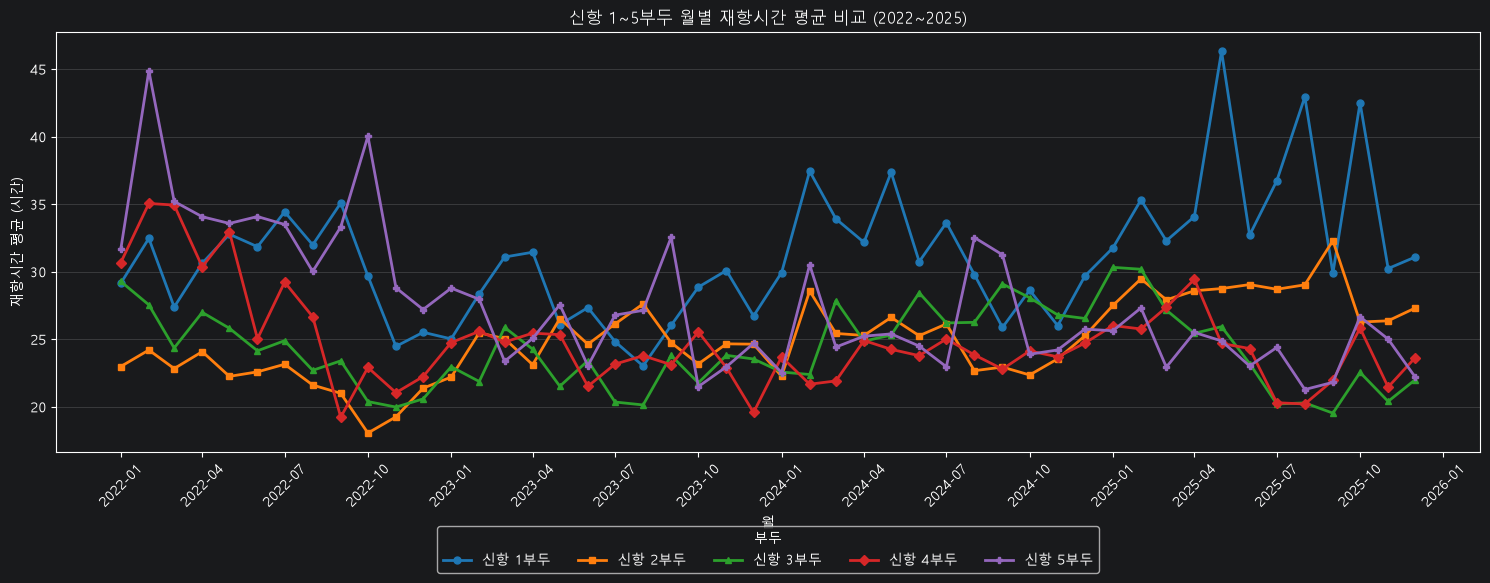

부두,신항 1부두 평균(시간),신항 2부두 평균(시간),신항 3부두 평균(시간),신항 4부두 평균(시간),신항 5부두 평균(시간)
연월,,,,,
2022-01,29.15,22.98,29.28,30.67,31.66
2022-02,32.47,24.20,27.55,35.05,44.87
2022-03,27.38,22.83,24.35,34.93,35.20
2022-04,30.63,24.08,26.99,30.36,34.07
2022-05,32.78,22.25,25.81,32.95,33.57
2022-06,31.85,22.59,24.14,25.04,34.08
2022-07,34.43,23.15,24.89,29.23,33.50
2022-08,31.99,21.61,22.70,26.67,30.02
2022-09,35.09,21.00,23.40,19.23,33.31


In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# EDA-Oak 데이터: 168시간 이상 재항한 기록을 제외한 데이터
DATA_PATH = Path("../data/record_except_168.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("C:/final/data/record_except_168.csv")

df = pd.read_csv(DATA_PATH)
df["입항일시"] = pd.to_datetime(df["입항일시"], errors="coerce")
df = df[df["입항일시"].between("2022-01-01", "2025-12-31 23:59:59")].copy()
df["부두번호"] = pd.to_numeric(
    df["계선장소"].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce",
)

monthly_mean = (
    df[df["부두번호"].between(1, 5)]
    .assign(월=lambda x: x["입항일시"].dt.to_period("M").dt.to_timestamp())
    .groupby(["월", "부두번호"], as_index=False)["재항시간"]
    .mean()
    .sort_values(["월", "부두번호"])
)
monthly_mean["부두"] = monthly_mean["부두번호"].map(
    lambda n: f"신항 {int(n)}부두"
)

plt.rcParams["font.family"] = ["Malgun Gothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.figure(figsize=(15, 6))
colors = sns.color_palette("tab10", 5)
markers = ["o", "s", "^", "D", "P"]
for n, color, marker in zip(range(1, 6), colors, markers):
    berth_data = monthly_mean[monthly_mean["부두번호"] == n]
    plt.plot(
        berth_data["월"],
        berth_data["재항시간"],
        label=f"신항 {n}부두",
        color=color,
        marker=marker,
        linewidth=2,
        markersize=5,
    )
plt.title("신항 1~5부두 월별 재항시간 평균 비교 (2022~2025)")
plt.xlabel("월")
plt.ylabel("재항시간 평균 (시간)")
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="부두", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.16))
plt.tight_layout()
plt.show()

# 월별·부두별 평균 재항시간 목록
monthly_mean_table = (
    monthly_mean.pivot(index="월", columns="부두", values="재항시간")
    .rename_axis("연월")
    .round(2)
)
monthly_mean_table.index = monthly_mean_table.index.strftime("%Y-%m")
monthly_mean_table = monthly_mean_table.reindex(
    columns=[f"신항 {n}부두" for n in range(1, 6)]
).rename(columns=lambda c: f"{c} 평균(시간)")
monthly_mean_table
